<div style="border-left:5px solid #67CBEE;padding:10px 16px;background:#F7F9FB;color:#19222D;margin:12px 0"><b>AMD Radeon · YOLO26 · Day 01</b><br><span style="color:#536273">算法 → 数据 → 训练 → 评测 → 证据。每一个结论都应由实际运行结果支撑。</span><br><span style="color:#536273">Algorithm → Data → Training → Evaluation → Evidence. Every conclusion must be backed by real execution results.</span></div>

# 01 / Lab A · 推理、BBox 与置信度阈值

**建议时长：20 分钟**　｜　学习路径：图像 → 检测结果 → 参数敏感性

> 请按顺序运行；运行结果必须来自自己的 GPU 环境，不可把示例文字当作实测数据。

---

# 01 / Lab A · Inference, BBoxes & Confidence Thresholds

**Suggested time: 20 minutes** | Learning path: image → detections → parameter sensitivity

> Run the cells in order; every result must come from your own GPU environment — never present the sample text as measured data.

## 实验目标
给同一张图片设置 `conf=0.10/0.25/0.50`，测量检测数量并保存图片。理解 **Score ≠ 真实正确概率**，置信度阈值只影响显示/保留哪些预测，不会修改模型权重。

**依赖**：先完成 00；预训练模型和示例图片可从官方地址下载（如云端不能访问外网，请提前上传缓存）。

### 预期输出（看形状，不是标准答案数字）
- 先显示一张样例图；随后每个阈值打印一行 `0.1 predictions: N -> <保存路径>`，保存的 jpg 上有带类别名和分数的框。
- 三张图**只差画的框数**——同样的框，阈值越高保留越少。
- `xyxy / confidence / class ID` 单元格打印三小段 numpy 数组（像素坐标、0–1 浮点、整数类别号）。
- IoU 单元格对给定两框打印一个严格介于 0 和 1 之间的数。

### 常见错误与下一步
| 症状 | 原因 | 下一步 |
|---|---|---|
| `FileNotFoundError` 找不到 `yolo26n.pt` | 没先跑 00 / 权重未缓存 | 先跑 00（它把模型固定到 `artifacts/`） |
| `NotImplementedError ... torchvision::nms` | torchvision 构建缺 GPU NMS 内核 | 换 uv 隔离 ROCm 栈（部署文档 §2B） |
| 自己换图后检出数随阈值升高而增加 | 通常是低对比/重复目标的边界情况 | 重新阅读单调性断言的报错信息；如实报告你看到的现象 |

---

## Goal
Run the same image at `conf=0.10/0.25/0.50`, count detections and save the images. Understand that **a score ≠ the true probability of correctness** — the confidence threshold only filters which predictions are kept/displayed; it never changes model weights.

**Prerequisite**: finish 00 first. The pretrained model and the sample image come from official sources (pre-upload them to the cache if your cloud has no external network).

### Expected Output (shape, not ground-truth numbers)
- One sample image is displayed, then for each threshold a line like `0.1 predictions: N -> <saved path>`; the saved jpg shows boxes with class names and scores.
- The three saved images differ **only in how many boxes are drawn** — same boxes, fewer of them as the threshold rises.
- The `xyxy / confidence / class ID` cell prints three small numpy arrays (pixel coordinates, 0–1 floats, integer class ids).
- The IoU cell prints a number strictly between 0 and 1 for the given boxes.

### Common Errors & Next Steps
| Symptom | Cause | Next step |
|---|---|---|
| `FileNotFoundError` on `yolo26n.pt` | Lab 00 not run / weights not cached | run 00 first (it pins the model into `artifacts/`) |
| `NotImplementedError ... torchvision::nms` | torchvision build lacks the GPU NMS kernel | switch to the uv-isolated ROCm stack (setup guide §2B) |
| counts **increase** as threshold rises on your own image | usually a very low-contrast/duplicate object case | re-check the monotonicity assertion message; report honestly what you saw |

In [1]:
from pathlib import Path
import os
import sys
import json

candidates = [Path.cwd(), Path.cwd().parent, Path('/workspace/YOLO26_ROCm_Day1_Labs')]
package = next((p for p in candidates if (p / 'course/lab_utils.py').exists()), None)
if package is None:
    raise FileNotFoundError('请先将 ZIP 完整解压，并从项目目录或 notebooks/ 目录启动 Jupyter。')
sys.path.insert(0, str(package))
from course.lab_utils import (root, ensure_dirs, load_config, save_config, write_json,
                              write_csv, system_info, require_rocm, sha256)

home = ensure_dirs()
cfg = load_config()
print('Project:', package, '\nPersistent output:', home)

Project: /workspace/yolo26-rocm-day1-labs 
Persistent output: /workspace/yolo_course_validation_linux_w7900_final


In [2]:
device = require_rocm()
from ultralytics import YOLO
import ultralytics
from PIL import Image
from IPython.display import display

model_path = home / 'artifacts/yolo26n.pt'
model = YOLO(str(model_path) if model_path.is_file() else cfg['model'])
print('Loaded:', model.ckpt_path if hasattr(model, 'ckpt_path') else cfg['model'])

AMD ROCm verified: AMD Radeon Pro W7900D HIP: 7.14.60850
Loaded: /workspace/yolo_course_validation_linux_w7900_final/artifacts/yolo26n.pt


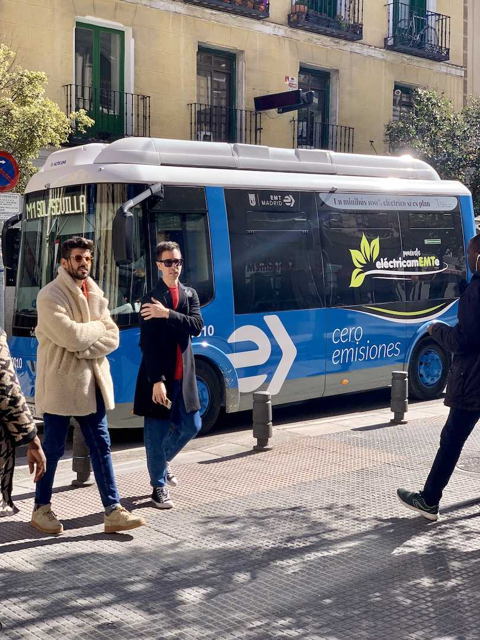

In [3]:
# 优先使用 Ultralytics 包内样例，否则下载官方公交车样例
example = Path(ultralytics.__file__).resolve().parent / 'assets/bus.jpg'
if not example.exists():
    example = home / 'assets/bus.jpg'
    if not example.exists():
        import urllib.request

        url = 'https://ultralytics.com/images/bus.jpg'
        try:
            urllib.request.urlretrieve(url, example)
        except Exception as exc:
            raise RuntimeError(f'无法下载示例图。请自行上传一张图片至 {example}。原因: {exc}')
assert example.is_file()
display(Image.open(example).resize((480, 640)))

In [4]:
from collections import Counter

thresholds = [0.10, 0.25, 0.50]
output_dir = home / 'assets/lab_a_thresholds'
output_dir.mkdir(parents=True, exist_ok=True)
summary = []
for threshold in thresholds:
    result = model.predict(source=str(example), device=device, conf=threshold, imgsz=640,
                           save=False, verbose=False)[0]
    boxes = result.boxes
    counts = Counter(int(k) for k in boxes.cls.cpu().tolist()) if boxes is not None else Counter()
    image_out = output_dir / f'conf_{threshold:.2f}.jpg'
    Image.fromarray(result.plot()[..., ::-1]).save(image_out)
    summary.append({'conf': threshold,
                    'detections': sum(counts.values()),
                    'classes': {model.names[k]: v for k, v in counts.items()},
                    'prediction_image': str(image_out)})
    print(threshold, 'predictions:', sum(counts.values()), '->', image_out)
write_json(home / 'reports/lab_a_predictions.json', summary)

0.1 predictions: 7 -> /workspace/yolo_course_validation_linux_w7900_final/assets/lab_a_thresholds/conf_0.10.jpg
0.25 predictions: 5 -> /workspace/yolo_course_validation_linux_w7900_final/assets/lab_a_thresholds/conf_0.25.jpg
0.5 predictions: 5 -> /workspace/yolo_course_validation_linux_w7900_final/assets/lab_a_thresholds/conf_0.50.jpg


In [5]:
# 让学生实际看到 xyxy / conf / cls 三组张量
example_result = model.predict(str(example), device=device, conf=0.25, verbose=False)[0]
if example_result.boxes is not None and len(example_result.boxes) > 0:
    print('xyxy:', example_result.boxes.xyxy[:3].cpu().numpy())
    print('confidence:', example_result.boxes.conf[:3].cpu().numpy())
    print('class ID:', example_result.boxes.cls[:3].cpu().numpy())
else:
    print('此阈值下没有检测目标；属于有效的实验结果。')

xyxy: [[          0      230.48       803.2       750.7]
 [     48.614       397.7      240.34      902.41]
 [     222.94      404.82      345.47      861.02]]
confidence: [     0.8806     0.87201     0.86081]
class ID: [          5           0           0]


In [6]:
# 练习：亲手计算两个框的交并比（几何示例，不是模型测出的 mAP）
from course.lab_utils import iou_xyxy

box_true = (160, 120, 480, 360)
box_pred = (200, 140, 500, 380)  # 学生可修改这个框，重新预测后再运行
MY_PREDICTED_IOU = 'TODO: 先预测——这两个框的 IoU 大概是多少？写一个 0 到 1 之间的数'

assert not str(MY_PREDICTED_IOU).startswith('TODO'), '请先写下你的预测（0–1 之间的数）再运行'
overlap = iou_xyxy(box_true, box_pred)
print('实际 IoU =', round(overlap, 4), '| 你的预测 =', MY_PREDICTED_IOU)
print('修改 box_pred 的坐标再运行一次，观察 IoU 怎么变；猜错不扣分，先预测才是目的')
assert 0 <= overlap <= 1

AssertionError: 请先写下你的预测（0–1 之间的数）再运行

In [ ]:
for item in summary:
    print(f"conf={item['conf']:.2f}  boxes={item['detections']}")
    display(Image.open(item['prediction_image']).resize((640, 480)))
assert all(summary[i]['detections'] >= summary[i + 1]['detections']
           for i in range(len(summary) - 1)), '同模型、同图像下阈值变大，检出数不应增加'
print('Threshold monotonicity: PASS')

### 思考题 / 面试必答
1. 为什么阈值升高，检测框数通常不会增加？
2. 将 `conf` 从 0.25 改为 0.50，模型参数发生改变了吗？
3. Confidence 0.95 是否保证有 95% 的概率检测正确？为什么？
4. 如果漏检严重，怎样评估降低阈值带来的 FP/Recall 权衡？

**交付**：3 张预测图片 + `reports/lab_a_predictions.json` + 简短结论。

---

### Think / Interview Questions
1. Why does the detection count usually not grow as the threshold rises?
2. Does changing `conf` from 0.25 to 0.50 change any model parameter?
3. Does a confidence of 0.95 mean a 95% chance of being correct? Why not?
4. If recalls are badly missed, how would you evaluate the FP/Recall trade-off of lowering the threshold?

**Deliverables**: 3 prediction images + `reports/lab_a_predictions.json` + a short conclusion.